In [38]:
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd().resolve().parent
DATA_PATH = BASE_DIR / 'data' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(DATA_PATH)

In [ ]:
df = pd.read_csv(DATA_PATH)
df.head(5)

In [ ]:
df.shape

In [ ]:
df.info()

In [ ]:
df.describe(include = "object")

In [ ]:
mask = df["TotalCharges"].str.strip().eq("")

df.loc[mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges" ]]


MISSING VALUES

- The dataset contains 11 empty values in the "TotalCharges" column.
- All 11 records have "tenure = 0".
- These records likely represent new customers with no accumulated charges.
- During preprocessing, we will convert "TotalCharges" to a numeric type and replace these specific missing values with "0".
- The original dataset will remain unchanged.

In [ ]:
df["Churn"].value_counts(normalize=True) * 100

In [ ]:
print("Dupliacted rows:", df.duplicated().sum())
print("Duplicated customer IDs:", df["customerID"].duplicated().sum())

In [ ]:
df["Contract"].value_counts()

In [ ]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

Customers with month-to-month contracts have a substantially higher churn rate (42.71%) than customers with one-year (11.27%) or two-year contracts (2.83%). Contract type appears to be a potentially useful predictive feature.

In [ ]:
df.groupby("Churn")["tenure"].describe()

Customers who churn have a substantially shorter average tenure (17.98 months) than customers who stay (37.57 months). This suggests that tenure may be an important predictive feature.

In [ ]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer tenure by churn status")
plt.show()

In [ ]:
pd.crosstab(
    df["tenure"],
    df["Churn"],
    normalize="index"
).round(2).head(15) * 100

In [ ]:
df.groupby("tenure")["Churn"].agg(
    customers = "count",
    churn_rate = lambda x: (x == "Yes").mean() * 100
).head(15)


In [ ]:
df.groupby("Churn")["MonthlyCharges"].describe()

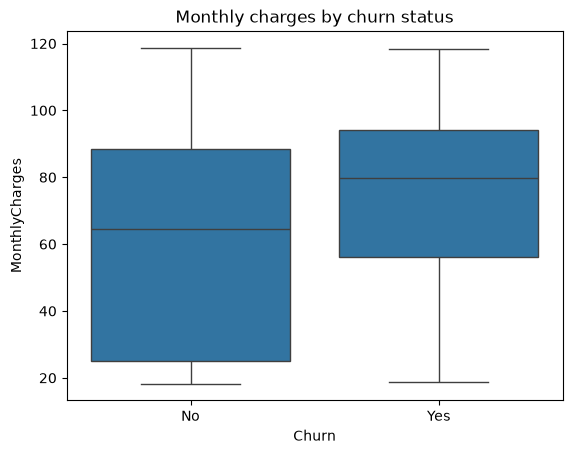

In [63]:
sns.boxplot(data = df, x = "Churn", y = "MonthlyCharges")
plt.title("Monthly charges by churn status")
plt.show()

Customers who churn have higher monthly charges on average (74.44) than customers who stay (61.27). However, the distributions overlap substantially, so monthly charges alone are unlikely to distinguish churned customers reliably.

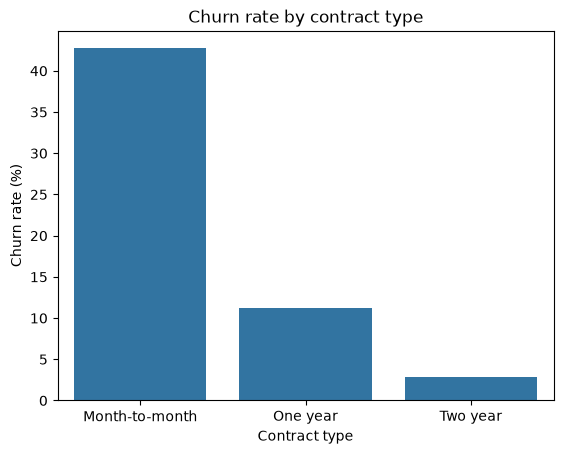

In [65]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize = "index") * 100

sns.barplot(x = contract_churn.index, y = contract_churn["Yes"])

plt.ylabel("Churn rate (%)")
plt.xlabel("Contract type")
plt.title("Churn rate by contract type")
plt.show()

EDA Conclusions

- The dataset contains 7,043 customers and 21 columns.
- No duplicated rows or customer IDs were found.
- "TotalCharges" contains 11 empty string values, all associated with "tenure = 0". These will be handled during preprocessing.
- The target variable is moderately imbalanced, with approximately 73.5% "No" and 26.5% "Yes".
- Customers with month-to-month contracts have a considerably higher churn rate (42.71%) than customers with two-year contracts (2.83%).
- Customers who churn have shorter average tenure (17.98 months) compared to customers who stay (37.57 months).
- Customers who churn have higher average monthly charges (74.44) compared to those who stay (61.27).

These findings suggest that contract type, tenure, and monthly charges may be useful predictive features. The observed relationships do not establish causation.